In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.game import *
from src.piece import *
from src.util import * 

pd.set_option('mode.chained_assignment', None)

In [74]:

def isUnSolvable(board):
    # Create df of empty triangles on the board.
    empty_triangles = board[board['piece'].isnull()]
    # Add Search Information.
    empty_triangles.loc[:, 'searched'] = False
    # Loop throgh each triangle.
    triangle_forest = []
    queue = []
    triangle_tree = []
    # Loop until everything is searched. Add an extra loop to plant the final tree in the forest.
    while empty_triangles['searched'].sum() < (empty_triangles['searched'].count() + 1):
    # for _ in range(10):
        if len(queue) > 0:
            # Pop the first item in the queue.
            indx, queue = queue[0], queue[1:]
            # Get the edges for the indx.
            edges = empty_triangles.loc[int(indx)][['edge_0', 'edge_1', 'edge_2']]
            # Simplify to edges that haven't been searched.
            non_searched_edges = empty_triangles[(empty_triangles.index.isin(edges)) & (~empty_triangles['searched'])]
            # Add each non-searched edge to the tree and queue.
            triangle_tree = np.append(triangle_tree, non_searched_edges.index.tolist())
            queue = np.append(queue, non_searched_edges.index.tolist())
            # Mark each edge as searched.
            empty_triangles.loc[empty_triangles.index.isin(non_searched_edges.index), 'searched'] = True
        else:
            if len(triangle_tree) > 0:
                triangle_forest.append(triangle_tree)
            # Get first unsearched vertex.
            indx = empty_triangles[~empty_triangles['searched']].index.min()
            if np.isnan(indx):
                break
            # Add triangle to the tree and queue.
            triangle_tree = np.array([int(empty_triangles.loc[indx].name)])
            queue = np.array([int(empty_triangles.loc[indx].name)])
            # Mark the triangle as searched.
            empty_triangles.loc[indx, 'searched'] = True
    lengths = [len(tri) for tri in triangle_forest]
    if len([tree for tree in lengths if tree == 1]) > 1:
        return True
    if len([tree for tree in lengths if tree == 2]) > 1:
        return True
    if len([tree for tree in lengths if tree == 3]) > 3:
        return True
    if len([tree for tree in lengths if tree == 4]) > 3:
        return True
    return False

In [78]:
# Setup Game
board, pieces = setupGame()
pieces = setPreviousPiece(pieces)
pieces = setPieceConfigs(pieces)
pieces = reorderPieces(pieces)
board_connections = pd.read_csv('Resources/Board.csv').set_index('id')
board = board.join(board_connections)
indices = getBoardIndices(board)

The Dice Rolls are 12, 17, 26, 31, 22, 44, 30


In [79]:
# Solve Game (Non Function for Debugging)
# solvedBoard, pieces, solved = solvePuzzle(board, indices, pieces)
# previous_piece = None
while not isSolved(board):
# for _ in range(50):
    # First Non-Placed Piece.
    for piece in pieces:
        if not piece.placed:
            break
    if piece.last_indx is None: starting_indx = 0
    else: starting_indx = piece.last_indx
    for indx in range(starting_indx + 1, indices.size):
        board, placed = placeIfValid(board, indices[indx], piece)
        if placed:
            if piece.name == 'Lavender5':
                print(f"Placed Lavender5 at {indices[indx]} w/ Roation:{piece.rotation} & Flipped:{piece.flipped}")
            if isSolved(board):
                break
            # If the board is unsolvable than don't place it.
            elif isUnSolvable(board):
                board = removePiece(board, piece)
            else:
                piece.placed = True
                piece.last_indx = indx
                break
    if not placed:
        if piece.rotation == 6 and piece.flipped:
            board = removePiece(board, piece.previous_piece)
            piece.previous_piece.placed = False
        if piece.rotation == 6:
            piece.rotateForwards()
            piece.rotation = 1
            piece.flipPiece()
            piece.last_indx = 0
        else:
            piece.rotateForwards()
            piece.rotation += 1
            piece.last_indx = 0

Placed Lavender5 at (0.5, -1.0) w/ Roation:1 & Flipped:False


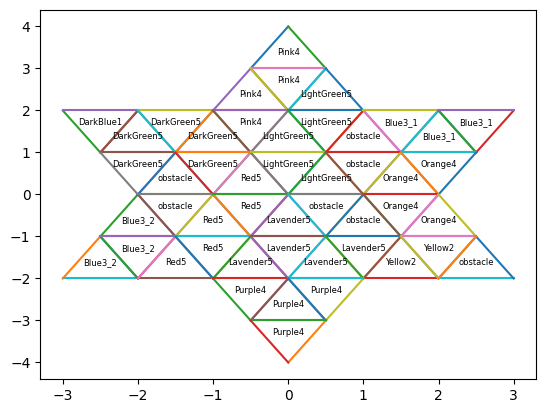

In [80]:
plotBoard(board)

<function matplotlib.pyplot.show(close=None, block=None)>

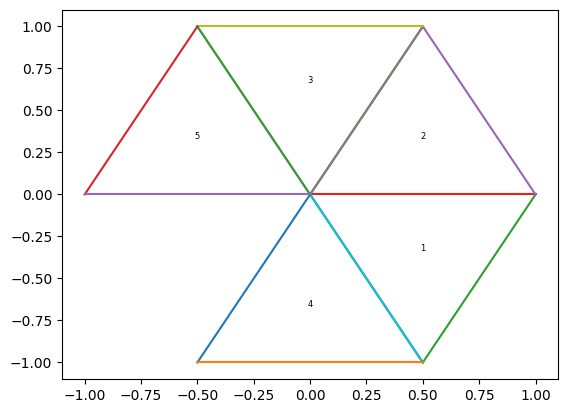

In [153]:
# Plot a Piece
fig, ax = plt.subplots()
indx = 0
for triangle in pieces[indx].data.index:
    ax.plot(
        [pieces[indx].data.loc[triangle, "v1_x"], pieces[indx].data.loc[triangle, "v2_x"]],
        [pieces[indx].data.loc[triangle, "v1_y"], pieces[indx].data.loc[triangle, "v2_y"]]
    )
    ax.plot(
        [pieces[indx].data.loc[triangle, "v2_x"], pieces[indx].data.loc[triangle, "v3_x"]],
        [pieces[indx].data.loc[triangle, "v2_y"], pieces[indx].data.loc[triangle, "v3_y"]]
    )
    ax.plot(
        [pieces[indx].data.loc[triangle, "v1_x"], pieces[indx].data.loc[triangle, "v3_x"]],
        [pieces[indx].data.loc[triangle, "v1_y"], pieces[indx].data.loc[triangle, "v3_y"]]
    )
    ax.annotate(pieces[indx].data.loc[triangle].name, (pieces[indx].data.loc[triangle, "center_x"], pieces[indx].data.loc[triangle, "center_y"]), size=6,  ha='center')
plt.show

In [152]:
pieces[indx].data.loc[triangle].name

np.int64(5)